# Session 11: Robust planned routes on 24 nights

**Question:** does planning a route against errors in the height of the moist layer, with a free-form planner, do better than the robust choice among the 45 fixed routes, and what does robustness cost compared with an ordinary plan?

**Builds on:** Session 8 chose robustly among the 45 fixed routes on 24 nights; Session 9 built the planner and showed its estimates must be re-timed and re-flown; Session 10 built the exact robust search in C++ and tested it on one night.

**Approach:**
1. For each of the 24 nights, the seven vertical scenarios of Sessions 7–8 (the field as given and moved up or down by 150, 300 and 600 m), on the FL340–FL390 grid of Session 10.
2. For each mass and λ, three planned paths: the **ordinary** plan (best for the unshifted field only), the **worst-case** robust plan and the **minimum-regret** robust plan. Each is re-timed along its own path until it repeats (as in Session 9).
3. Every path is re-flown through the full pipeline in all seven fields; all comparisons use the re-flown values.
4. Comparison with Session 8's worst-case choice among the fixed routes (same scenarios, same flight levels), and a speed comparison of the C++ core with its pure-Python version.

**Assumptions:** as Sessions 8–10. Fuel is computed in the unshifted field (the scenarios move contrail conditions, not the aircraft). Each robust search is limited to 2 minutes and 10 million partial paths; a search that reaches a limit returns the best path its bounds found, with a certified gap (no path can be better by more than the gap), is not re-timed, and is reported separately from the exact results.

**Version note:** the robust search was strengthened for this session, with answers unchanged (the same brute-force and C++/Python tests pass): (1) a joint lower bound on fuel and contrail distance per scenario instead of separate bounds; (2) a Lagrangian bound (a weighted average of the scenarios, weights tuned by subgradient steps), which also proves many paths optimal without any search; (3) the time and size limits above, returning a certified gap instead of failing. On artificial weather with real 72 t fuel rates, a search that did not finish in 2 minutes before now takes 0.01 s.

**Sections:** 1. Setup · 2. One night, step by step · 3. All 24 nights · 4. Checks · 5. Robust planner vs fixed routes · 6. Cost of robustness · 7. C++ vs Python · 8. Figures · Results

## 1. Setup

The C++ core from Session 10 must be rebuilt once for this session (it gained a time limit and a tighter bound): `python -m pip install --no-build-isolation --force-reinstall --no-deps ./cpp`.

In [1]:
import sys, gc, time, warnings
from dataclasses import replace
from pathlib import Path
SRC = (Path("..") / "src").resolve()
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from contrail_routing import config
from contrail_routing.met import load_era5_checked, load_region
from contrail_routing.geometry import flight_from_path, flight_level_to_m, haversine_km
from contrail_routing.evaluate import evaluate_route
from contrail_routing.performance import fuel_burn
from contrail_routing.scenarios import shift_field
from contrail_routing.planner import build_cost_model, plan_timed, climb_kg_per_level
from contrail_routing.robust import robust_plan, robust_plan_timed, contrail_core

warnings.filterwarnings("ignore", message=r"\s*Met data appears to have originated from ECMWF")
pd.set_option("display.width", 220)
assert contrail_core is not None, "build the C++ core first (see above)"
assert "max_seconds" in contrail_core.robust_plan.__doc__, "rebuild the C++ core for Session 11 (see above)"

results_dir = Path("..") / "results"
fig_dir = results_dir / "figures"
s8_dir, s11_dir = results_dir / "session8", results_dir / "session11"
nights_dir = s11_dir / "nights"                      # one file per night, so a re-run resumes
nights_dir.mkdir(parents=True, exist_ok=True)

DATES = config.STUDY_DATES
SPEED = config.CRUISE_SPEED_MS
N_STAGES = 60
OFFSETS_KM = np.arange(-300, 301, 25)
FLIGHT_LEVELS = np.array([340, 350, 360, 370, 380, 390])
VERTICAL_M = {"base": 0.0, "up150": 150.0, "up300": 300.0, "up600": 600.0,
              "down150": -150.0, "down300": -300.0, "down600": -600.0}
SCEN = list(VERTICAL_M)
MASSES = {"light_56t": 56000.0, "model_default": None,
          "heavy_68t": 68000.0, "very_heavy_72t": 72000.0}
LAMBDAS = [0.1, 1.0, 10.0]
LIMITS = {"max_labels": 10_000_000, "max_seconds": 120.0}
GC_KM = float(haversine_km(*config.ORIGIN, *config.DESTINATION))

fuel8 = pd.read_csv(s8_dir / "fuel_by_night.csv")
dec8 = pd.read_csv(s8_dir / "robust_decisions_by_night.csv")

def fuel_rates(date, mass_case):
    """kg/km per flight level (inf outside the envelope) and start mass, from the Session 8 great circle."""
    g = fuel8[(fuel8["date"] == date) & (fuel8["mass_case"] == mass_case)].set_index("route")
    gc_rows = g.loc[[f"GC0_FL{fl}" for fl in FLIGHT_LEVELS]]
    rate = np.where(gc_rows["feasible"], gc_rows["fuel_kg"] / GC_KM, np.inf)
    return rate, float(gc_rows.loc[gc_rows["feasible"], "start_mass_kg"].mean())
print(f"{len(DATES)} nights x {len(MASSES)} masses x {len(LAMBDAS)} lambdas x 3 plans, each re-flown in {len(SCEN)} fields")

24 nights x 4 masses x 3 lambdas x 3 plans, each re-flown in 7 fields


## 2. One night, step by step

`run_night` builds the seven shifted fields, then for each mass and λ plans the ordinary and the two robust paths (each re-timed along its own path), re-flies each in all seven fields, and saves one row per path. A night already saved is loaded instead of recomputed.

In [2]:
def load_fields(date):
    met, _ = load_era5_checked((f"{date}T00", f"{date}T06"), config.LEVELS_FINE,
                               config.REGION_LON, config.REGION_LAT)
    region = load_region(met, config.REGION_LON, config.REGION_LAT)
    met.data.close()
    return {name: shift_field(region, up_m=dz) for name, dz in VERTICAL_M.items()}

def build_models(date, fields, rate, climb, delay_s=None, only_base=False):
    names = ["base"] if only_base else SCEN
    return [build_cost_model(fields[n], config.ORIGIN, config.DESTINATION, pd.Timestamp(f"{date} 00:00"),
                             SPEED, N_STAGES, OFFSETS_KM, FLIGHT_LEVELS, rate, climb, delay_s=delay_s)
            for n in names]

def refly(p, date, fields, mass_kg, name):
    """Fly a path through the full pipeline in every field: PCR km per scenario, fuel in the unshifted field."""
    fl = flight_from_path(p["lon"], p["lat"], flight_level_to_m(p["flight_level"].astype(float)),
                          pd.Timestamp(f"{date} 00:00"), SPEED, name=name)
    pcr, base_track = {}, None
    for n in SCEN:
        track = evaluate_route(fl, fields[n])
        pcr[f"pcr_pipe_{n}"] = float(track.loc[track["PCR"] > 0, "leg_km"].sum())
        if n == "base":
            base_track = track
    fb = fuel_burn(base_track, config.AIRCRAFT, SPEED, takeoff_mass_kg=mass_kg)
    return {"fuel_pipe_kg": fb["fuel_kg"], "within_envelope": fb["within_envelope"], **pcr}

def run_night(date, verbose=False):
    path = nights_dir / f"{date}.csv"
    if path.exists():
        return pd.read_csv(path)
    fields = load_fields(date)
    rows = []
    for mc, mass in MASSES.items():
        rate, m_est = fuel_rates(date, mc)
        climb = climb_kg_per_level(mass or m_est)
        models0 = build_models(date, fields, rate, climb)
        rebuild_all = lambda d: build_models(date, fields, rate, climb, d)
        rebuild_base = lambda d: build_models(date, fields, rate, climb, d, only_base=True)[0]
        for lam in LAMBDAS:
            for kind in ["ordinary", "worst_case", "min_regret"]:
                t0 = time.time()
                row = {"date": date, "mass_case": mc, "lambda": lam, "kind": kind}
                try:
                    if kind == "ordinary":
                        p = plan_timed(rebuild_base, models0[0], lam, SPEED, max_dk=1)
                        est = {f"pcr_est_{n}": np.nan for n in SCEN}
                        est["pcr_est_base"] = p["pcr_km"]
                        stats = {"labels": np.nan}
                    else:
                        p = robust_plan_timed(rebuild_all, models0, lam, SPEED, rule=kind, max_dk=1,
                                              max_iter=3, **LIMITS)
                        est = {f"pcr_est_{n}": v for n, v in zip(SCEN, p["pcr_km"])}
                        stats = {"labels": p["labels_created"], "stopped": p["stopped"], "gap_kg": p["gap"],
                                 "proved_by_bounds": p["proved_by_bounds"],
                                 "lower_bound": p["lower_bound_lagrangian"], "objective_est": p["objective"]}
                    row.update({"status": "ok", "iterations": p["iterations"], "converged": p["converged"],
                                "fuel_est_kg": p["fuel_kg"], **est, **stats,
                                "levels": "/".join(map(str, sorted(set(p["flight_level"].tolist())))),
                                "level_changes": int(np.count_nonzero(np.diff(p["flight_level"]))),
                                "max_offset_km": float(np.abs(p["offset_km"]).max()),
                                **refly(p, date, fields, mass, f"{date}_{mc}_{lam}_{kind}")})
                except RuntimeError as err:                 # no feasible path (not expected)
                    row.update({"status": str(err)})
                row["seconds"] = time.time() - t0
                rows.append(row)
                if verbose:
                    tag = row.get("stopped") or ("proved by bounds" if row.get("proved_by_bounds") is True else "")
                    print(f"  {mc:15s} lambda={lam:<5} {kind:10s} {row['status']:4s} {str(tag):16s} {row['seconds']:6.1f} s", flush=True)
    out = pd.DataFrame(rows)
    out.to_csv(path, index=False)
    del fields
    gc.collect()
    return out

t0 = time.time()
night0 = run_night("2022-03-01", verbose=True)
print(f"\n2022-03-01 in {time.time() - t0:.0f} s")

ERA5 [175, 190, 200, 210, 220, 230, 240, 250, 275, 300] hPa: all 7 hours complete.
  light_56t       lambda=0.1   ordinary   ok                       0.2 s
  light_56t       lambda=0.1   worst_case ok   proved by bounds    1.7 s
  light_56t       lambda=0.1   min_regret ok   proved by bounds    2.3 s
  light_56t       lambda=1.0   ordinary   ok                       0.4 s
  light_56t       lambda=1.0   worst_case ok   proved by bounds    1.8 s
  light_56t       lambda=1.0   min_regret ok   proved by bounds    2.6 s
  light_56t       lambda=10.0  ordinary   ok                       0.4 s
  light_56t       lambda=10.0  worst_case ok   proved by bounds    1.7 s
  light_56t       lambda=10.0  min_regret ok   proved by bounds    2.3 s
  model_default   lambda=0.1   ordinary   ok                       0.3 s
  model_default   lambda=0.1   worst_case ok   proved by bounds    1.8 s
  model_default   lambda=0.1   min_regret ok                       2.8 s
  model_default   lambda=1.0   ordinary  

## 3. All 24 nights

Expect several minutes per night, longer on nights with moist air near the cruise levels of heavy aircraft. Each night is saved as it finishes, so the cell can be stopped and re-run; finished nights load in a moment.

In [3]:
t_start = time.time()
allres = []
for i, date in enumerate(DATES, 1):
    t0 = time.time()
    r = run_night(date)
    allres.append(r)
    n_stop = int(r["stopped"].fillna("").astype(str).str.len().gt(0).sum()) if "stopped" in r else 0
    print(f"[{i:2d}/{len(DATES)}] {date} {time.time() - t0:5.0f} s | robust searches stopped by a limit: "
          f"{n_stop} | slowest plan {r['seconds'].max():5.0f} s", flush=True)
print(f"Total {(time.time() - t_start) / 60:.1f} min")
res = pd.concat(allres, ignore_index=True)
ok = res["status"] == "ok"
res["stopped"] = res["stopped"].fillna("").astype(str).replace("nan", "")
res["exact"] = ok & (res["stopped"] == "")
pipe_cols = [f"pcr_pipe_{n}" for n in SCEN]
res["pcr_pipe_worst_km"] = res[pipe_cols].max(axis=1)
res["J_worst_pipe"] = res["fuel_pipe_kg"] + res["lambda"] * res["pcr_pipe_worst_km"]
res.to_csv(s11_dir / "robust_plans_by_night.csv", index=False)

ERA5 [175, 190, 200, 210, 220, 230, 240, 250, 275, 300] hPa: all 7 hours complete.
[ 1/24] 2022-01-01   846 s | robust searches stopped by a limit: 3 | slowest plan   135 s
ERA5 [175, 190, 200, 210, 220, 230, 240, 250, 275, 300] hPa: all 7 hours complete.
[ 2/24] 2022-01-15    64 s | robust searches stopped by a limit: 0 | slowest plan     3 s
ERA5 [175, 190, 200, 210, 220, 230, 240, 250, 275, 300] hPa: all 7 hours complete.
[ 3/24] 2022-02-01   822 s | robust searches stopped by a limit: 4 | slowest plan   230 s
ERA5 [175, 190, 200, 210, 220, 230, 240, 250, 275, 300] hPa: all 7 hours complete.
[ 4/24] 2022-02-15    64 s | robust searches stopped by a limit: 0 | slowest plan     3 s
[ 5/24] 2022-03-01     0 s | robust searches stopped by a limit: 0 | slowest plan     5 s
ERA5 [175, 190, 200, 210, 220, 230, 240, 250, 275, 300] hPa: all 7 hours complete.
[ 6/24] 2022-03-15    63 s | robust searches stopped by a limit: 0 | slowest plan     3 s
ERA5 [175, 190, 200, 210, 220, 230, 240, 250,

## 4. Checks

Searches stopped by the limits (with their certified gaps), re-timing that did not settle, paths outside the flight envelope, and the planner's contrail estimate against the re-flown pipeline value in every scenario.

In [4]:
print("Plans by status:", res["status"].value_counts().to_dict())
rob_rows = res[ok & (res["kind"] != "ordinary")]
print(f"Robust searches: {len(rob_rows)}; proved optimal by the bounds alone: "
      f"{int((rob_rows['proved_by_bounds'] == True).sum())}; exact after search: "
      f"{int(((rob_rows['proved_by_bounds'] != True) & (rob_rows['stopped'] == '')).sum())}; "
      f"stopped by a limit: {int((rob_rows['stopped'] != '').sum())}")
stopped = rob_rows[rob_rows["stopped"] != ""]
if len(stopped):
    print("Stopped searches by mass, lambda and kind, with the certified gap (kg; % of fuel):")
    stopped = stopped.assign(gap_pct=100 * stopped["gap_kg"] / stopped["fuel_est_kg"])
    print(stopped.groupby(["mass_case", "lambda", "kind"])[["gap_kg", "gap_pct"]]
          .agg(["count", "median", "max"]).round(1).to_string())
print("Re-timing: plans by number of iterations", res.loc[ok, "iterations"].value_counts().sort_index().to_dict(),
      "| not converged:", int((~res.loc[ok, "converged"].astype(bool)).sum()))
print("Paths outside the flight envelope when re-flown:", int((~res.loc[ok, "within_envelope"].astype(bool)).sum()))

err = pd.concat([(res.loc[ok, f"pcr_est_{n}"] - res.loc[ok, f"pcr_pipe_{n}"]).rename(n) for n in SCEN], axis=1)
print("\nPlanner estimate minus pipeline, PCR km (robust plans in all scenarios; ordinary plans in 'base'):")
e = err.stack().dropna()
print(e.describe()[["count", "mean", "min", "50%", "max"]].round(1).to_string())
print("Share of estimates within 30 km:", round(float((e.abs() <= 30).mean()), 3))
w = res.loc[ok & (res["kind"] == "worst_case")]
print("\nWorst-case plans: estimated vs re-flown worst-scenario PCR km")
print(pd.DataFrame({"estimated": w[[f"pcr_est_{n}" for n in SCEN]].max(axis=1),
                    "re-flown": w["pcr_pipe_worst_km"]}).describe().loc[["mean", "50%", "max"]].round(1).to_string())
print("\nSearch size (robust plans): labels", res.loc[ok & (res["kind"] != "ordinary"), "labels"].describe()[["50%", "max"]].to_dict(),
      "| seconds per plan", res.loc[ok, "seconds"].describe()[["50%", "max"]].round(1).to_dict())

Plans by status: {'ok': 864}
Robust searches: 576; proved optimal by the bounds alone: 275; exact after search: 285; stopped by a limit: 16
Stopped searches by mass, lambda and kind, with the certified gap (kg; % of fuel):
                                 gap_kg               gap_pct             
                                  count median    max   count median   max
mass_case      lambda kind                                                
heavy_68t      1.0    min_regret      1   90.1   90.1       1    1.7   1.7
                      worst_case      1   98.0   98.0       1    1.8   1.8
               10.0   min_regret      1  688.2  688.2       1   12.4  12.4
                      worst_case      2  478.9  721.2       2    8.5  13.1
light_56t      1.0    min_regret      1  141.7  141.7       1    3.1   3.1
                      worst_case      1  132.6  132.6       1    2.9   2.9
               10.0   worst_case      1  264.6  264.6       1    5.2   5.2
model_default  1.0    min_r

## 5. Robust planner vs fixed routes

Session 8's worst-case choice among the fixed FL340–FL390 routes, against the worst-case planned path, both re-flown in all seven fields: J_worst = fuel + λ × (PCR km in the worst scenario). Gain = fixed − planner (kg fuel-equivalent; positive = planner better).

In [5]:
fixed = dec8[dec8["rule"] == "worst_case"].copy()
fixed["J_worst_fixed"] = fixed["fuel_kg"] + fixed["lambda"] * fixed["pcr_worst_km"]
cmp_ = (res[ok & (res["kind"] == "worst_case")].assign(exact_search=lambda d: d["stopped"] == "")
        .merge(fixed[["date", "mass_case", "lambda", "route", "fuel_kg", "pcr_worst_km", "J_worst_fixed"]]
               .rename(columns={"route": "fixed_route", "fuel_kg": "fixed_fuel_kg", "pcr_worst_km": "fixed_pcr_worst_km"}),
               on=["date", "mass_case", "lambda"]))
cmp_["gain_kg"] = cmp_["J_worst_fixed"] - cmp_["J_worst_pipe"]
summary = (cmp_.groupby(["mass_case", "lambda"])["gain_kg"]
           .agg(nights="count", median="median", mean="mean", min="min", max="max",
                better=lambda g: int((g > 0.5).sum()), worse=lambda g: int((g < -0.5).sum())).round(1))
summary["exact_searches"] = cmp_.groupby(["mass_case", "lambda"])["exact_search"].sum().astype(int)
print("Gain of the worst-case planned path over the fixed routes' worst-case choice (kg fuel-equivalent):")
print(summary.loc[list(MASSES)].to_string())
print("\nWorst-scenario PCR km, planned vs fixed (all cases):")
print(pd.DataFrame({"planned": cmp_["pcr_pipe_worst_km"], "fixed": cmp_["fixed_pcr_worst_km"]})
      .describe().loc[["mean", "50%", "max"]].round(1).to_string())
print("Cases where the planned path is clean in every scenario but the fixed choice is not:",
      int(((cmp_["pcr_pipe_worst_km"] == 0) & (cmp_["fixed_pcr_worst_km"] > 0)).sum()), "of", len(cmp_))
cmp_.to_csv(s11_dir / "planner_vs_fixed_worst_case.csv", index=False)
summary.to_csv(s11_dir / "planner_vs_fixed_summary.csv")

Gain of the worst-case planned path over the fixed routes' worst-case choice (kg fuel-equivalent):
                       nights  median   mean    min     max  better  worse  exact_searches
mass_case      lambda                                                                     
light_56t      0.1         24     0.0    1.5   -0.0    18.0       3      0              24
               1.0         24     0.0   27.0  -76.4   243.6       7      2              23
               10.0        24     0.0  354.1 -190.1  1775.8       8      3              23
model_default  0.1         24     9.1   11.4   -0.0    70.1      14      0              24
               1.0         24    23.4   46.4  -15.9   236.8      16      1              23
               10.0        24    13.6  331.6 -232.1  1663.0      14      3              22
heavy_68t      0.1         24     0.0   12.6   -0.0    81.2      11      0              24
               1.0         24    39.8   52.3  -54.9   196.0      18      1        

## 6. Cost of robustness

The robust plans against the ordinary plan for the same night, mass and λ (all re-flown): extra fuel, and the change in worst-scenario PCR km.

In [6]:
wide = res[ok].pivot_table(index=["date", "mass_case", "lambda"], columns="kind",
                           values=["fuel_pipe_kg", "pcr_pipe_worst_km", "pcr_pipe_base", "J_worst_pipe"])
rows = []
for kind in ["worst_case", "min_regret"]:
    d = pd.DataFrame({
        "extra_fuel_kg": wide[("fuel_pipe_kg", kind)] - wide[("fuel_pipe_kg", "ordinary")],
        "extra_fuel_pct": 100 * (wide[("fuel_pipe_kg", kind)] / wide[("fuel_pipe_kg", "ordinary")] - 1),
        "worst_pcr_reduction_km": wide[("pcr_pipe_worst_km", "ordinary")] - wide[("pcr_pipe_worst_km", kind)],
        "base_pcr_change_km": wide[("pcr_pipe_base", kind)] - wide[("pcr_pipe_base", "ordinary")],
        "J_worst_saving_kg": wide[("J_worst_pipe", "ordinary")] - wide[("J_worst_pipe", kind)]}).dropna()
    d["kind"] = kind
    rows.append(d.reset_index())
rob = pd.concat(rows, ignore_index=True)
print("Robust plans vs the ordinary plan (re-flown), by mass: median [max]")
agg = rob.groupby(["kind", "mass_case"]).agg(
    cases=("extra_fuel_kg", "size"),
    extra_fuel_pct_median=("extra_fuel_pct", "median"), extra_fuel_pct_max=("extra_fuel_pct", "max"),
    worst_pcr_cut_km_median=("worst_pcr_reduction_km", "median"), worst_pcr_cut_km_max=("worst_pcr_reduction_km", "max"),
    cases_with_cut=("worst_pcr_reduction_km", lambda g: int((g > 0.5).sum())))
print(agg.round(2).to_string())
wc = rob[rob["kind"] == "worst_case"]
print("\nWorst-case plans whose re-flown worst case is worse than the ordinary plan's (J_worst, > 0.5 kg):",
      int((wc["J_worst_saving_kg"] < -0.5).sum()), "of", len(wc), "(possible only through estimate errors or stopped searches)")
rob.to_csv(s11_dir / "robust_vs_ordinary_by_night.csv", index=False)

Robust plans vs the ordinary plan (re-flown), by mass: median [max]
                           cases  extra_fuel_pct_median  extra_fuel_pct_max  worst_pcr_cut_km_median  worst_pcr_cut_km_max  cases_with_cut
kind       mass_case                                                                                                                      
min_regret heavy_68t          72                    0.0               10.35                     69.0                993.60              48
           light_56t          72                    0.0               10.55                      0.0                952.20              18
           model_default      72                    0.0               11.30                     41.4                703.80              48
           very_heavy_72t     72                    0.0               11.10                     96.6                966.67              48
worst_case heavy_68t          72                    0.0               10.35                     69

## 7. C++ vs Python

The same search in C++ and in pure Python on 2022-03-01 (great-circle timing, free level, both rules). Python is run only where C++ needed fewer than 300,000 partial paths, so this section stays under a few minutes; for the larger searches only the C++ time is reported.

In [7]:
fields0 = load_fields("2022-03-01")
rows = []
for mc, mass in MASSES.items():
    rate, m_est = fuel_rates("2022-03-01", mc)
    models = build_models("2022-03-01", fields0, rate, climb_kg_per_level(mass or m_est))
    for lam in LAMBDAS:
        for rule in ["worst_case", "min_regret"]:
            t0 = time.time()
            rc = robust_plan(models, lam, rule=rule, max_dk=1, engine="cpp", **LIMITS)
            t_cpp = time.time() - t0
            labels = rc["labels_created"]
            t_py, same = np.nan, None
            if labels < 300_000 and not rc["stopped"]:
                t0 = time.time()
                rp = robust_plan(models, lam, rule=rule, max_dk=1, engine="python", **LIMITS)
                t_py = time.time() - t0
                same = bool(np.array_equal(rc["j_idx"], rp["j_idx"]) and np.array_equal(rc["k_idx"], rp["k_idx"])
                            and rc["labels_created"] == rp["labels_created"])
            rows.append({"mass_case": mc, "lambda": lam, "rule": rule, "labels": labels, "seconds_cpp": t_cpp,
                         "seconds_python": t_py, "speed_up": t_py / t_cpp, "same_path": same})
bench = pd.DataFrame(rows)
print(bench.round(3).to_string(index=False))
print("\nSpeed-up where both ran: median", round(float(bench["speed_up"].median()), 1),
      "| min", round(float(bench["speed_up"].min()), 1), "| max", round(float(bench["speed_up"].max()), 1),
      "| all compared paths identical:", bool(bench["same_path"].dropna().all()))
bench.to_csv(s11_dir / "cpp_vs_python_2022-03-01.csv", index=False)

ERA5 [175, 190, 200, 210, 220, 230, 240, 250, 275, 300] hPa: all 7 hours complete.
     mass_case  lambda       rule  labels  seconds_cpp  seconds_python  speed_up  same_path
     light_56t     0.1 worst_case       0        0.017           1.348    79.214       True
     light_56t     0.1 min_regret       0        0.429           1.801     4.194       True
     light_56t     1.0 worst_case       0        0.017           1.326    77.887       True
     light_56t     1.0 min_regret       0        0.144           1.231     8.555       True
     light_56t    10.0 worst_case       0        0.009           0.647    71.641       True
     light_56t    10.0 min_regret       0        0.444           1.764     3.968       True
 model_default     0.1 worst_case       0        0.009           0.654    71.529       True
 model_default     0.1 min_regret      95        0.200          10.063    50.298       True
 model_default     1.0 worst_case       0        0.017           1.366    79.912       Tr

## 8. Figures

Left: gain of the worst-case planned path over the fixed routes' worst-case choice on each night (λ = 1), by mass. Right: cost of robustness against the reduction in worst-scenario contrail distance, worst-case plans vs ordinary plans (λ = 1).

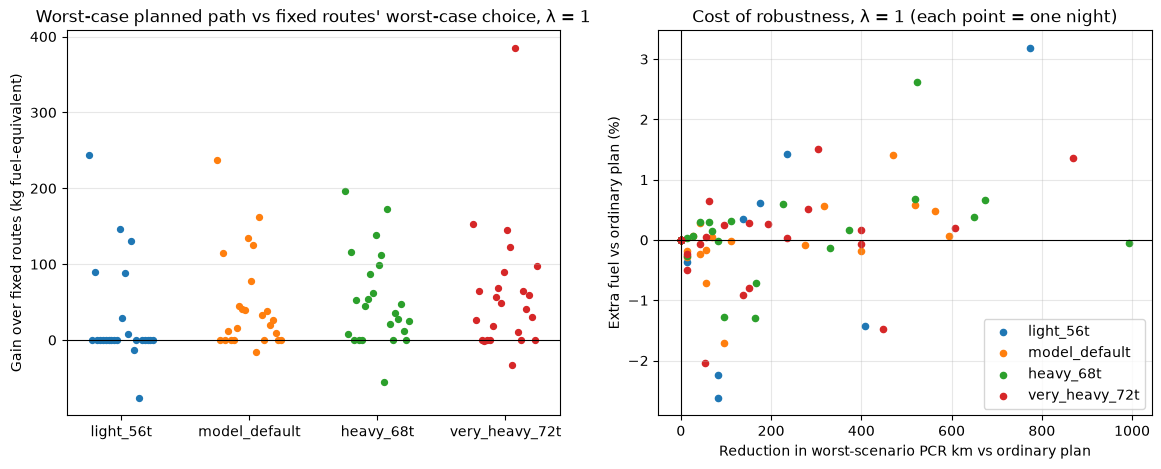

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
c1 = cmp_[cmp_["lambda"] == 1.0]
for k, mc in enumerate(MASSES):
    v = c1.loc[c1["mass_case"] == mc, "gain_kg"].values
    ax.scatter(np.full(len(v), k) + np.linspace(-0.25, 0.25, len(v)), v, s=18)
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(range(len(MASSES)))
ax.set_xticklabels(list(MASSES))
ax.set_ylabel("Gain over fixed routes (kg fuel-equivalent)")
ax.set_title("Worst-case planned path vs fixed routes' worst-case choice, λ = 1")
ax.grid(alpha=0.3, axis="y")

ax = axes[1]
r1 = rob[(rob["kind"] == "worst_case") & (rob["lambda"] == 1.0)]
for mc in MASSES:
    d = r1[r1["mass_case"] == mc]
    ax.scatter(d["worst_pcr_reduction_km"], d["extra_fuel_pct"], s=20, label=mc)
ax.axhline(0, color="k", lw=0.8)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Reduction in worst-scenario PCR km vs ordinary plan")
ax.set_ylabel("Extra fuel vs ordinary plan (%)")
ax.set_title("Cost of robustness, λ = 1 (each point = one night)")
ax.legend()
ax.grid(alpha=0.3)
fig.savefig(fig_dir / "session11_robust_planner.png", dpi=150, bbox_inches="tight")
plt.show()

## Results
 
### Setup
 
24 nights × 4 masses (56 t, model estimate ≈64 t, 68 t, 72 t) × λ = 0.1, 1, 10 kg/km × 3 plans = 864 planned paths on a grid of 60 stages × 25 lateral offsets (±300 km) × 6 flight levels (FL340–FL390), against the seven vertical scenarios of Session 8 (the field as given and moved up or down by 150, 300 and 600 m). The **ordinary** plan is best for the unshifted field; the **worst-case** plan minimises fuel + λ × PCR km in the worst scenario; the **minimum-regret** plan minimises the largest excess over the best plan for each scenario. Robust plans were re-timed up to 3 times, ordinary plans up to 5; each robust search was limited to 2 minutes and 10 million partial paths. Every path was re-flown through the full pipeline in all seven fields, and all comparisons use the re-flown values.
 
### Checks
 
- **All 864 plans found a path**; none outside the flight envelope when re-flown.
- **Search outcomes (576 robust searches):**
| Rule | Proved optimal by the bounds alone | Exact after search | Stopped by the 2-minute limit |
|---|---|---|---|
| Worst case | 176 | 101 | 11 |
| Minimum regret | 99 | 184 | 5 |
| **Total** | **275 (48%)** | **285 (49%)** | **16 (2.8%)** |
 
  The median search needed 66 partial paths and 1.8 s; the largest exact search needed 1.6 million partial paths and 135 s.
- **The 16 stopped searches** came from 6 nights (1 Jan, 1 Feb, 15 Apr, 1 Aug, 15 Aug, 1 Oct), all at λ = 1 (7) or λ = 10 (9). Each returned a real path, re-flown like the others, with a certified gap (no path on the grid is better by more than this): 1.7–3.1% of fuel at λ = 1 and 4.0–13.9% at λ = 10 (the four largest, 10.9–13.9%, all on 2022-02-01). Stopped searches are not re-timed. The gap is a ceiling, not the loss: 8 of the 11 stopped worst-case paths still beat the fixed routes, including the largest gain of the session.
- **Planner estimate vs pipeline:** 4,320 comparisons (robust plans in all seven scenarios, ordinary plans in the unshifted field): −69.8 to +30.0 km of PCR, mean −0.4 km, 99.6% within 30 km, the same accuracy as Session 9. Worst-case plans: estimated worst-scenario PCR 90.1 km on average, re-flown 92.4 km.
- **Re-timing:** 797 of 864 plans repeated after 2 plans. 42 did not settle: the 16 stopped searches (not re-timed by design), 20 robust plans at the 3-plan cap and 6 ordinary plans at the 5-plan cap. Their last plan was re-flown like the others.
- **C++ vs Python** (2022-03-01, 24 searches): identical paths and identical numbers of partial paths in every case. The speed-up was 61× at the median (4–80×), but that night was easy. All worst-case searches were proved by the bounds, so 72–80× there measures the bound computation. For minimum regret it was 4–50×, because both versions first run the same seven ordinary plans in Python. The largest search compared had 52,805 partial paths (C++ 0.97 s, Python 30.1 s); the searches with millions of partial paths were not run in Python.
- **Run time:** 74 minutes for the 24 nights, of which the 6 nights with stopped searches took 52 minutes. 95 automated tests pass.
### Findings
 
#### 1. The robust planner beats the fixed routes' worst-case choice on most nights for 64–72 t aircraft
 
Gain = J_worst of Session 8's worst-case choice among the fixed FL340–FL390 routes − J_worst of the re-flown worst-case planned path, J_worst = fuel + λ × PCR km in the worst of the seven scenarios (kg fuel-equivalent, 24 nights):
 
| λ | Mass | Median gain | Max gain | Worst loss | Nights better | Nights worse |
|---|---|---|---|---|---|---|
| 0.1 | 56 t / ≈64 t / 68 t / 72 t | 0 / 9.1 / 0 / 13.0 | 18–81 | 0 | 3 / 14 / 11 / 15 | 0 |
| 1 | 56 t / ≈64 t / 68 t / 72 t | 0 / 23.4 / 39.8 / 45.1 | 196–385 | −16 to −76 | 7 / 16 / 18 / 17 | 2 / 1 / 1 / 2 |
| 10 | 56 t / ≈64 t / 68 t / 72 t | 0 / 13.6 / 41.3 / 108.9 | 1,663–4,133 | −190 to −287 | 8 / 14 / 16 / 16 | 3 each |
 
- In Session 9 the ordinary planner rarely beat the best fixed route (median gain 0 except for heavy aircraft). Here the planned path is better on 155 of 288 cases and worse on 18. Across all cases its median worst-scenario contrail distance is 0 km against 13.8 km for the fixed choice (mean 92 vs 126 km), and 12 times it was clean in every scenario where the fixed choice was not.
- The gains are lopsided: 46,058 kg fuel-equivalent in total against 1,770 kg of losses. The largest gains come from a few nights with moist air at most levels, e.g. 4,133 kg at λ = 10 for 72 t on 2022-08-15 (124 km of worst-scenario contrail instead of 572 km for 344 kg more fuel).
- **Why the planned path lost on 18 cases** (each checked against its search status and the planner's own estimate):
  - 3 stopped searches (λ = 1; 16–76 kg);
  - 3 plans whose re-timing did not settle (2022-06-01, λ = 10; 94–152 kg): the re-flown path met 13.8 km more contrail than estimated;
  - 12 exact, settled plans (9 at λ = 10) where the planner's own estimate was already worse than the fixed route. The fixed routes are smooth curves that do not lie exactly on the planner's 25 km grid, and the planner's cost model differs from the pipeline on them by −36 to +31 km of PCR (Session 9 check), up to about 350 kg at λ = 10. These two causes are not separated here.
#### 2. Robustness is usually free, and buys the most for heavy aircraft
 
Worst-case plans vs the ordinary plan for the same night, mass and λ (re-flown, 72 cases per mass):
 
| Mass | Cases with less worst-scenario PCR | Median cut (km) | Max cut (km) | Median extra fuel | Max extra fuel |
|---|---|---|---|---|---|
| 56 t | 22 | 0 | 952 | 0.0% | 10.6% |
| ≈64 t | 50 | 55 | 704 | 0.0% | 11.3% |
| 68 t | 52 | 69 | 994 | 0.0% | 10.4% |
| 72 t | 52 | 117 | 994 | 0.0% | 11.1% |
 
- Where the worst case improved (176 of 288 cases), the median extra fuel was 0.12%, and 69 of those cuts cost no extra fuel at all.
- Extra fuel above 5% occurred only at λ = 10 (16 cases), always for large cuts (110–952 km). The maximum is 0.4% at λ = 0.1 and 3.2% at λ = 1.
- 65 worst-case plans burn *less* fuel than the ordinary plan. This is expected: the ordinary plan spends fuel avoiding contrails that exist only in the unshifted field.
- Robust plans change level more often than ordinary plans (56 t: 26% vs 15% of plans; ≈64 t: 67% vs 36%; 68 t: 68% vs 43%; 72 t: 72% vs 62%).
- 6 of 288 worst-case plans were worse than the ordinary plan in re-flown J_worst, all at λ = 0.1 and by 0.6–8.0 kg, all from exact, settled searches: small differences between the planner's estimate and the pipeline.
#### 3. Worst case and minimum regret usually agree
 
The two robust rules gave the same re-flown fuel and worst-scenario PCR (within 0.5) in 181 of 288 cases. Minimum regret was harder to prove: 99 of its searches were settled by the bounds alone, against 176 for worst case.
 
### Limitations
 
- The search is exact on the planner's grid, not over every possible path. 16 searches stopped at the time limit with certified gaps of up to 13.9% of fuel.
- The robust plan optimises the planner's estimate, which differs from the pipeline by up to 70 km of PCR. At λ = 10 this is worth up to 700 kg and explains some of the losses above.
- The scenarios are the assumed height errors of Sessions 7–8 (±150–600 m, equally weighted), not measured ERA5 errors, and only FL340–FL390 is used because larger shifts move FL310–FL330 outside the data.
- One city pair, one departure time, no wind and constant true airspeed, as in Sessions 1–10.
 